# V4 inference: classification performance versus number of bases K

This notebook evaluates the metrics on the validation set selected. It uses the checkpoint's training normalization and trusts the existing compression report. No compression, training, report revalidation, or hashing is performed.

K is the actual number of distinct bases.

The official test set is reserved for a later evaluation after choosing the compression procedure.

The analysis measures association; it cannot establish that increasing K will improve accuracy. Class composition and small sample sizes matter. Validation has also been used for checkpoint selection, so these results are exploratory.

Currently selection:
- version: v4
- model: best model according to validation
- validation set: 5000 images, obtained from a stratified split of the training set (10% of it)

In [ ]:
from pathlib import Path, PureWindowsPath
from datetime import datetime, timezone
from time import perf_counter
import json
import math
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import torch
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

CONFIG = {
    "local": True,
    "colab_root": "/content/drive/MyDrive/Colab Notebooks/AARHUS INTERNSHIP",
    "checkpoint": "output/models/valid_v4_cumulative_rank_adaptive_MSB_20261022/best.pth",  # select which model you want to refer to
    "manifest": "output/v4_cumulative_rank_adaptive_MSB/train/manifest_train.json",
    "k_report": "output/cumulative_audit_2026-10-01/per_image.jsonl",
    "originals": "data/cifar-10_resized/train",
    "results": "runs/inference_Kbased",
    "batch_size": 32,
}
# For Colab, copy src/ml_setup, the report, checkpoint, manifest and extracted
# training NPZ files to Drive. Paths may also be absolute (e.g. local /content data).
if not CONFIG["local"]:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_ROOT = Path(CONFIG["colab_root"])
def resolve_path(value):
    path = Path(value)
    return path if path.is_absolute() else PROJECT_ROOT / path
sys.path.insert(0, str(PROJECT_ROOT / "src"))
from ml_setup.models import CustomResNet50
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

Device: cuda


## 1. Load the V4 checkpoint and its validation samples

Use `model_state_dict` from the selected checkpoint: choose `best.pth` for the best validation checkpoint. IDs in `split_info.val_ids` match the training notebook's `Path(file).stem`, including the `.network` suffix. For joining with the report, only the filename suffix is removed. Old machine-specific report directories are ignored.

Only essential checks are applied: V4 checkpoint, saved validation membership, compatible class labels and complete K coverage. Report K values are used as supplied; they are not compared with IGD files or recomputed.

In [13]:
# *DEBUGGING CELL*
CHECKPOINT_PATH = resolve_path(CONFIG["checkpoint"])
checkpoint = torch.load(CHECKPOINT_PATH, map_location="cpu", weights_only=True)
checkpoint.get("split_info").get("val_ids")
checkpoint["idx_to_class"]

{0: 'airplane',
 1: 'automobile',
 2: 'bird',
 3: 'cat',
 4: 'deer',
 5: 'dog',
 6: 'frog',
 7: 'horse',
 8: 'ship',
 9: 'truck'}

In [14]:
CHECKPOINT_PATH = resolve_path(CONFIG["checkpoint"])
MANIFEST_PATH = resolve_path(CONFIG["manifest"])
REPORT_PATH = resolve_path(CONFIG["k_report"])

checkpoint = torch.load(CHECKPOINT_PATH, map_location="cpu", weights_only=True)
if checkpoint.get("representation") != "cumulative-rank-u16-v4":
    raise ValueError("Select a valid checkpoint.")

# get only the images that has been used in the validation set
val_ids = set(checkpoint["split_info"]["val_ids"])

manifest = json.loads(MANIFEST_PATH.read_text(encoding="utf-8"))

# get the right samples, from the manifest, only for val_ids
samples = [s for s in manifest["samples"] if Path(s["file"]).stem in val_ids] 
if not val_ids or len(samples) != len(val_ids):
    raise ValueError("The manifest must contain every saved validation sample exactly once.")

# get the indexes and the names of the classes
idx_to_class = {int(k): v for k, v in checkpoint["idx_to_class"].items()}
if {int(v): k for k, v in manifest["class_to_idx"].items()} != idx_to_class:
    raise ValueError("Manifest and checkpoint class labels differ.")
CLASS_NAMES = [idx_to_class[i] for i in range(checkpoint["num_classes"])]
NUM_CLASSES = len(CLASS_NAMES)

MEAN = float(checkpoint["normalization"]["mean"])
STD = float(checkpoint["normalization"]["std"])

def image_id(path):
    name = PureWindowsPath(str(path)).name
    return name.removesuffix(".npz").removesuffix(".network").removesuffix(".igd")

with REPORT_PATH.open(encoding="utf-8") as stream:
    report_rows = [json.loads(line) for line in stream if line.strip()]
k_by_id = {image_id(r["path"]): r["num_bases"] for r in report_rows}
missing = [s["file"] for s in samples if image_id(s["file"]) not in k_by_id]
if missing:
    raise ValueError(f"Missing K for {len(missing)} validation samples, e.g. {missing[:5]}")
rows = pd.DataFrame({
    "file": [s["file"] for s in samples],
    "image_id": [image_id(s["file"]) for s in samples],
    "target": [s["label"] for s in samples],
    "K": [k_by_id[image_id(s["file"])] for s in samples],
})
rows["true_class"] = rows["target"].map(idx_to_class)
print("Checkpoint:", CHECKPOINT_PATH)
print("Epoch:", checkpoint["completed_epochs"], "| validation samples:", len(rows))
display(rows.groupby("true_class").size().rename("support").to_frame())

Checkpoint: C:\Users\Edward\Desktop\AARHUS\output\models\valid_v4_cumulative_rank_adaptive_MSB_20261022\best.pth
Epoch: 10 | validation samples: 5000


,support
true_class,
airplane,500
automobile,500
bird,500
cat,500
deer,500
dog,500
frog,500
horse,500
ship,500


## 2. One inference pass

Inputs are raw `z_u16` maps converted to float32 and normalized with training mean/std. There is no augmentation or division by 65535. Individual cross-entropy is computed directly from logits. Loader order is preserved for joining predictions to samples.

In [ ]:
class ValidationMaps(Dataset):
    def __len__(self):
        return len(samples)

    def __getitem__(self, index):
        sample = samples[index]
        with np.load(MANIFEST_PATH.parent / sample["file"], allow_pickle=False) as archive:
            z = archive["z_u16"].astype(np.float32)
        x = torch.from_numpy(z).unsqueeze(0)
        return (x - MEAN) / STD, sample["label"]

loader = DataLoader(ValidationMaps(), batch_size=CONFIG["batch_size"], shuffle=False, num_workers=0)
model = CustomResNet50(pretrained=False, num_classes=NUM_CLASSES, in_channels=1)
model.load_state_dict(checkpoint["model_state_dict"], strict=True)
model.to(DEVICE).eval()
loss_batches, probability_batches = [], []
start = perf_counter()
with torch.inference_mode():
    for x, y in tqdm(loader, desc="Validation inference (over all batches)"):
        logits = model(x.to(DEVICE))
        losses = F.cross_entropy(logits, y.to(DEVICE), reduction="none")
        if not torch.isfinite(losses).all():
            raise ValueError("Non-finite inference loss.")
        loss_batches.append(losses.cpu().numpy())
        probability_batches.append(logits.softmax(dim=1).cpu().numpy())
evaluation_seconds = perf_counter() - start
probabilities = np.concatenate(probability_batches)
rows["loss"] = np.concatenate(loss_batches)
rows["prediction"] = probabilities.argmax(axis=1)
rows["predicted_class"] = rows["prediction"].map(idx_to_class)
rows["p_true"] = probabilities[np.arange(len(rows)), rows["target"].to_numpy()]
rows["confidence"] = probabilities.max(axis=1)
rows["correct"] = rows["prediction"] == rows["target"]
for i, name in enumerate(CLASS_NAMES):
    rows[f"p_{name}"] = probabilities[:, i]
print(f"Inference completed in {evaluation_seconds:.1f} s")

Validation inference:   0%|          | 0/157 [00:00<?, ?it/s]

Inference completed in 41.3 s


## 3. Analysis settings and reusable metrics

From here onward, rerun cells without repeating inference. Thresholds are exploratory candidates, not a selected compression policy. `K < K_min` is the low-K definition throughout.

Accuracy intervals are 95% Wilson intervals. Empty groups have undefined metrics. Per-class recall is undefined for absent classes; balanced accuracy averages recall only over supported classes, whose number is reported. It helps inspect class composition but does not eliminate all confounding.

In [16]:
ANALYSIS = {
    "thresholds": [8, 16, 32, 64, 128, 256, 512, 1024],
    "selected_k_min": 128,
    "minimum_bin_support": 100,
    "top_loss_fraction": 0.05,
    "gallery_per_group": 4,
}

def confusion_counts(frame):
    cm = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=np.int64)
    np.add.at(cm, (frame["target"].to_numpy(dtype=int), frame["prediction"].to_numpy(dtype=int)), 1)
    return cm

def describe(frame):
    n = len(frame)
    cm = confusion_counts(frame)
    support = cm.sum(axis=1)
    recall = np.divide(np.diag(cm), support, out=np.full(NUM_CLASSES, np.nan), where=support > 0)
    p = frame["correct"].mean() if n else np.nan
    if n:
        z = 1.959963984540054
        den = 1 + z*z/n
        center = (p + z*z/(2*n))/den
        half = z*np.sqrt(p*(1-p)/n + z*z/(4*n*n))/den
        lower, upper = center-half, center+half
    else:
        lower = upper = np.nan
    return {"n": n, "population_pct": 100*n/len(rows),
            "accuracy_pct": 100*p, "accuracy_ci_low_pct": 100*lower,
            "accuracy_ci_high_pct": 100*upper, "mean_loss": frame["loss"].mean(),
            "error_count": int((~frame["correct"]).sum()),
            "supported_classes": int((support > 0).sum()),
            "balanced_accuracy_pct": 100*np.nanmean(recall) if n else np.nan}

def class_metrics(frame, group):
    cm = confusion_counts(frame)
    support, predicted = cm.sum(axis=1), cm.sum(axis=0)
    tp = np.diag(cm)
    recall = np.divide(tp, support, out=np.full(NUM_CLASSES, np.nan), where=support > 0)
    precision = np.divide(tp, predicted, out=np.full(NUM_CLASSES, np.nan), where=predicted > 0)
    return pd.DataFrame({"group": group, "class": CLASS_NAMES, "support": support,
                         "recall": recall, "precision": precision})

overall = pd.DataFrame([{"group": "All validation", **describe(rows)}])
display(overall)
display(rows["K"].describe(percentiles=[.01, .05, .1, .25, .5, .75, .9, .95, .99]).to_frame())

,group,n,population_pct,accuracy_pct,accuracy_ci_low_pct,accuracy_ci_high_pct,mean_loss,error_count,supported_classes,balanced_accuracy_pct
0,All validation,5000,100.0,81.2,80.09322,82.258876,0.638533,940,10,81.2


,K
count,5000.000000
mean,1634.414600
std,2507.448102
min,2.000000
1%,2.000000
5%,2.000000
10%,8.000000
25%,346.000000
50%,933.000000
75%,1924.250000


## 4. Distribution and performance across K ranges

Start with power-of-two boundaries. Adjacent ranges are merged until they reach the configured minimum support; any small final range is merged backward. If the whole population is smaller than the minimum, one range remains. These disjoint ranges complement the cumulative threshold analysis below.

,K_range,n,population_pct,accuracy_pct,accuracy_ci_low_pct,accuracy_ci_high_pct,mean_loss,error_count,supported_classes,balanced_accuracy_pct
0,"[0, 4)",296,5.92,52.027027,46.346226,57.655889,1.595437,142,10,46.620261
1,"[4, 8)",201,4.02,64.179104,57.341767,70.484631,1.293785,72,10,58.791745
2,"[8, 32)",168,3.36,76.785714,69.846084,82.527773,0.876943,39,10,75.963553
3,"[32, 64)",106,2.12,87.735849,80.141366,92.690879,0.547803,13,10,85.999278
4,"[64, 128)",109,2.18,81.651376,73.351413,87.796326,0.539889,20,10,82.855148
5,"[128, 256)",354,7.08,83.333333,79.097626,86.853369,0.611073,59,10,84.095895
6,"[256, 512)",800,16.00,81.375000,78.529624,83.920502,0.605314,149,10,82.293816
7,"[512, 1024)",1011,20.22,86.547972,84.305790,88.513466,0.457085,136,10,86.536063
8,"[1024, 2048)",1141,22.82,84.312007,82.087026,86.306724,0.515370,179,10,85.137574
9,"[2048, 4096)",538,10.76,84.386617,81.076812,87.208845,0.527996,84,10,83.202989


class,airplane,automobile,bird,cat,deer,dog,frog,horse,ship,truck
K_range,,,,,,,,,,
"[0, 4)",0.735294,0.687500,0.052632,0.424242,0.222222,0.307692,0.428571,0.515152,0.629630,0.659091
"[4, 8)",0.888889,0.694444,0.615385,0.692308,0.700000,0.461538,0.166667,0.250000,0.653846,0.756098
"[8, 32)",0.875000,0.800000,0.692308,0.800000,0.900000,0.600000,0.533333,0.785714,0.760000,0.850000
"[32, 64)",1.000000,1.000000,0.750000,0.818182,0.428571,0.714286,0.888889,1.000000,1.000000,1.000000
"[64, 128)",0.900000,0.888889,0.750000,0.800000,0.909091,0.857143,0.647059,0.833333,0.900000,0.800000
"[128, 256)",0.903226,0.785714,0.818182,0.718750,0.790698,0.916667,0.755556,0.833333,0.961538,0.925926
"[256, 512)",0.911111,0.896552,0.750000,0.666667,0.822430,0.721519,0.782609,0.838384,0.918033,0.922078
"[512, 1024)",0.900000,0.905263,0.814815,0.747253,0.913043,0.826923,0.819820,0.918182,0.897196,0.911111
"[1024, 2048)",0.968085,0.927835,0.882883,0.736000,0.829457,0.718519,0.784483,0.871795,0.854701,0.940000


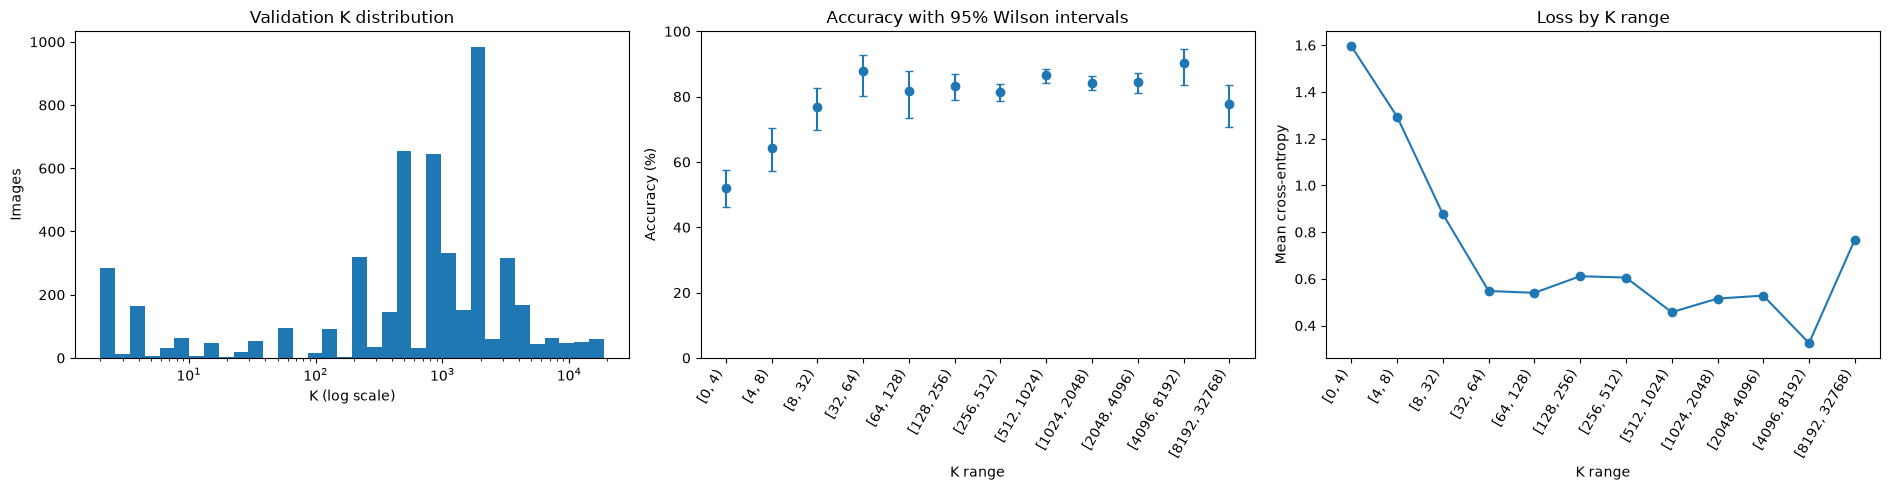

In [17]:
max_k = int(rows["K"].max())
raw_edges = [0] + [2**p for p in range(1, max(2, max_k.bit_length()+1))]
raw_edges = sorted(set(raw_edges + [max_k+1]))
edges, pending = [0], 0
for left, right in zip(raw_edges[:-1], raw_edges[1:]):
    pending += int(((rows["K"] >= left) & (rows["K"] < right)).sum())
    if pending >= ANALYSIS["minimum_bin_support"]:
        edges.append(right)
        pending = 0
if edges[-1] < raw_edges[-1]:
    if pending and len(edges) > 1:
        edges[-1] = raw_edges[-1]
    else:
        edges.append(raw_edges[-1])
rows["K_range"] = pd.cut(rows["K"], bins=edges, right=False)
bin_records, bin_classes = [], []
for interval, frame in rows.groupby("K_range", observed=True):
    bin_records.append({"K_range": str(interval), **describe(frame)})
    bin_classes.append(class_metrics(frame, str(interval)))
bin_summary = pd.DataFrame(bin_records)
bin_per_class = pd.concat(bin_classes, ignore_index=True)
display(bin_summary)
display(bin_per_class.pivot(index="group", columns="class", values="recall").reindex(bin_summary["K_range"]))

fig, axes = plt.subplots(1, 3, figsize=(19, 5))
axes[0].hist(rows["K"], bins=np.geomspace(max(1, rows["K"].min()), max_k+1, 35))
axes[0].set(xscale="log", xlabel="K (log scale)", ylabel="Images", title="Validation K distribution")
x = np.arange(len(bin_summary))
y = bin_summary["accuracy_pct"].to_numpy()
axes[1].errorbar(x, y, yerr=np.vstack([y-bin_summary["accuracy_ci_low_pct"], bin_summary["accuracy_ci_high_pct"]-y]), fmt="o", capsize=3)
axes[1].set(ylabel="Accuracy (%)", ylim=(0, 100), title="Accuracy with 95% Wilson intervals")
axes[2].plot(x, bin_summary["mean_loss"], "o-")
axes[2].set(ylabel="Mean cross-entropy", title="Loss by K range")
for ax in axes[1:]:
    ax.set_xticks(x, bin_summary["K_range"], rotation=60, ha="right")
    ax.set_xlabel("K range")
fig.tight_layout()
plt.show()
distribution_figure = fig

## 5. Candidate thresholds and confusion matrices

Compare each low-K subset with its complement and the full validation set. Threshold comparisons overlap and should not be treated as independent experiments. Support tables and class recall help identify changes in class composition.

For the selected threshold, show only row-normalized confusion matrices for all three groups. Absent classes are marked N/A. Small subsets require cautious interpretation.

The selection score is `S_1_pp = error_coverage_pct - coverage_pct`, with both terms expressed in percent. Coverage is the fraction of all validation images below the threshold; error coverage is the fraction of all validation errors below the threshold. Higher scores identify subsets containing a disproportionately large share of errors relative to their size. Scores are defined only for non-empty low-K subsets when validation contains errors; complement rows are not candidates. The highest-scoring candidate is selected automatically (ties favor the smaller threshold). This heuristic selects a candidate for compression experiments, not a measured compression benefit.


,K_min,group,n,population_pct,accuracy_pct,accuracy_ci_low_pct,accuracy_ci_high_pct,mean_loss,error_count,supported_classes,balanced_accuracy_pct,coverage_pct,error_coverage_pct,S_1_score,selected
0,8,low_K,497,9.94,56.941650,52.551557,61.225257,1.473441,214,10,51.794965,9.94,22.765957,12.825957,False
1,8,remaining,4503,90.06,83.877415,82.774528,84.922550,0.546383,726,10,84.049080,90.06,77.234043,NaN,False
2,16,low_K,591,11.82,60.406091,56.408229,64.269550,1.379110,234,10,55.991840,11.82,24.893617,13.073617,False
3,16,remaining,4409,88.18,83.987299,82.875306,85.040119,0.539263,706,10,84.221467,88.18,75.106383,NaN,False
4,32,low_K,665,13.30,61.954887,58.206212,65.566238,1.322747,253,10,58.143786,13.30,26.914894,13.614894,True
5,32,remaining,4335,86.70,84.152249,83.034971,85.209053,0.533573,687,10,84.390787,86.70,73.085106,NaN,False
6,64,low_K,771,15.42,65.499351,62.074489,68.770531,1.216205,266,10,62.765086,15.42,28.297872,12.877872,False
7,64,remaining,4229,84.58,84.062426,82.928414,85.134613,0.533216,674,10,84.289728,84.58,71.702128,NaN,False
8,128,low_K,880,17.60,67.500000,64.335165,70.512714,1.132434,286,10,65.486947,17.60,30.425532,12.825532,False
9,128,remaining,4120,82.40,84.126214,82.978642,85.210206,0.533040,654,10,84.344483,82.40,69.574468,NaN,False


Selected K_min=32: score=13.61


,group,n,population_pct,accuracy_pct,accuracy_ci_low_pct,accuracy_ci_high_pct,mean_loss,error_count,supported_classes,balanced_accuracy_pct
0,All validation,5000,100.0,81.200000,80.093220,82.258876,0.638533,940,10,81.200000
1,K < 32,665,13.3,61.954887,58.206212,65.566238,1.322747,253,10,58.143786
2,K >= 32,4335,86.7,84.152249,83.034971,85.209053,0.533573,687,10,84.390787


,group,class,support,recall,precision
0,All validation,airplane,500,0.912000,0.737864
1,All validation,automobile,500,0.862000,0.841797
2,All validation,bird,500,0.776000,0.881818
3,All validation,cat,500,0.702000,0.682879
4,All validation,deer,500,0.820000,0.791506
5,All validation,dog,500,0.704000,0.800000
6,All validation,frog,500,0.760000,0.952381
7,All validation,horse,500,0.834000,0.854508
8,All validation,ship,500,0.860000,0.838207
9,All validation,truck,500,0.890000,0.797491


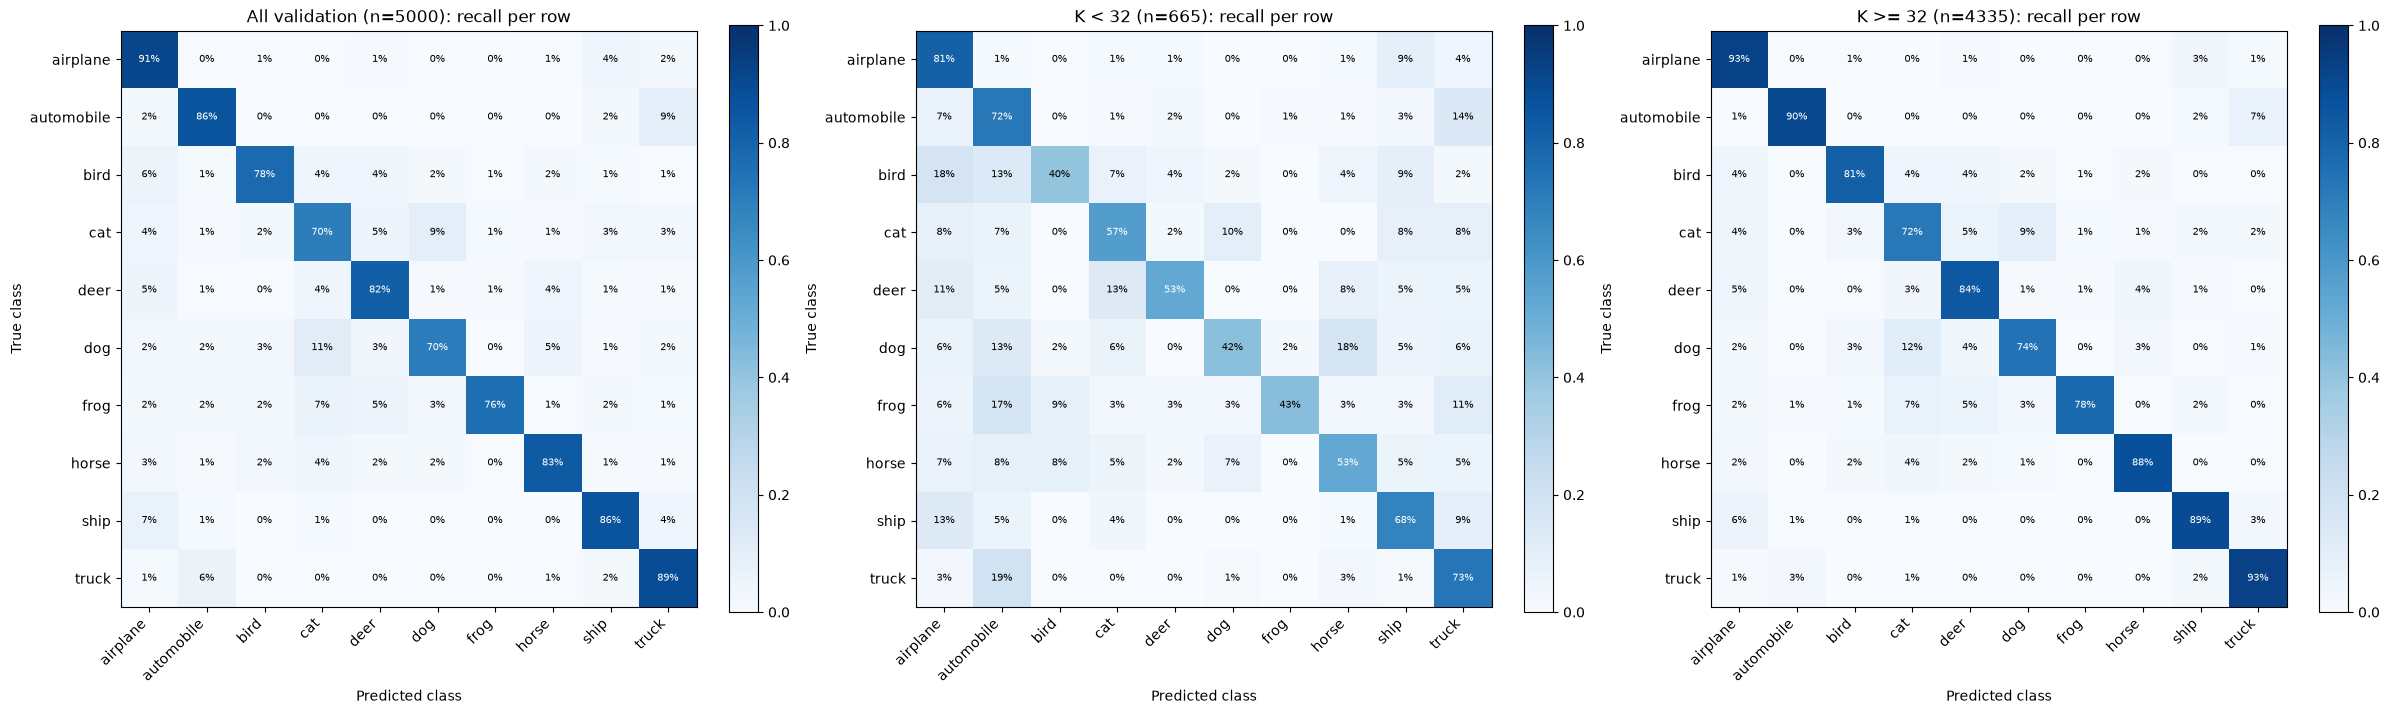

In [37]:
threshold_records = []
for threshold in sorted(set(ANALYSIS["thresholds"] + [ANALYSIS["selected_k_min"]])):
    for name, mask in [("low_K", rows["K"] < threshold), ("remaining", rows["K"] >= threshold)]:
        threshold_records.append({"K_min": threshold, "group": name, **describe(rows[mask])})
threshold_summary = pd.DataFrame(threshold_records)
total_errors = int((~rows["correct"]).sum())
threshold_summary["coverage_pct"] = threshold_summary["population_pct"]
threshold_summary["error_coverage_pct"] = (
    100 * threshold_summary["error_count"] / total_errors if total_errors else np.nan
)
threshold_summary["S_1_score"] = np.where(
    (threshold_summary["group"] == "low_K") & (threshold_summary["n"] > 0),
    threshold_summary["error_coverage_pct"] - threshold_summary["coverage_pct"],
    np.nan,
)
candidates = threshold_summary.dropna(subset=["S_1_score"])
if candidates.empty:
    raise ValueError("S_1 requires validation errors and at least one non-empty low-K subset.")
best_candidate = candidates.sort_values(
    ["S_1_score", "K_min"], ascending=[False, True]
).iloc[0]
K_MIN = int(best_candidate["K_min"])
threshold_summary["selected"] = (
    (threshold_summary["group"] == "low_K") & (threshold_summary["K_min"] == K_MIN)
)
display(threshold_summary)
print(f"Selected K_min={K_MIN}: score={best_candidate['S_1_score']:.2f}")
groups = {"All validation": rows, f"K < {K_MIN}": rows[rows["K"] < K_MIN],
          f"K >= {K_MIN}": rows[rows["K"] >= K_MIN]}
selected_summary = pd.DataFrame([{"group": name, **describe(frame)} for name, frame in groups.items()])
selected_per_class = pd.concat([class_metrics(frame, name) for name, frame in groups.items()], ignore_index=True)
display(selected_summary)
display(selected_per_class)

confusions = {}
fig, axes = plt.subplots(1, 3, figsize=(24, 7))
for ax, (name, frame) in zip(axes, groups.items()):
    cm = confusion_counts(frame)
    support = cm.sum(axis=1)
    normalized = np.divide(cm, support[:, None], out=np.zeros_like(cm, dtype=float), where=support[:, None] > 0)
    confusions[name] = {"counts": cm.tolist(), "row_normalized": normalized.tolist(), "support": support.tolist()}
    im = ax.imshow(normalized, cmap="Blues", vmin=0, vmax=1)
    fig.colorbar(im, ax=ax, fraction=.046)
    ax.set(xticks=range(NUM_CLASSES), yticks=range(NUM_CLASSES), xticklabels=CLASS_NAMES,
           yticklabels=CLASS_NAMES, xlabel="Predicted class", ylabel="True class",
           title=f"{name} (n={len(frame)}): recall per row")
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            label = f"{normalized[i,j]:.0%}" if support[i] else "N/A"
            ax.text(j, i, label, ha="center", va="center", fontsize=7,
                    color="white" if normalized[i,j] > 0.5 else "black")
fig.tight_layout()
plt.show()
confusion_figure = fig

## 6. High-loss cases and concentration of errors

The top fraction includes all images ranked by individual cross-entropy, including correctly classified images if they fall within that fraction. Ties use manifest order. Also export misclassified images ranked by loss separately.

The enrichment ratio compares low-K prevalence in the high-loss group with its prevalence in the full population. A ratio above one indicates overrepresentation. Error coverage answers a different question: what fraction of all classification errors is below the threshold? Neither measure alone demonstrates a causal benefit from increasing K.

In [19]:
fraction = ANALYSIS["top_loss_fraction"]
if not 0 < fraction <= 1:
    raise ValueError("top_loss_fraction must be in (0, 1].")
worst = rows.sort_values("loss", ascending=False, kind="stable").head(math.ceil(len(rows)*fraction))
ranked_errors = rows[~rows["correct"]].sort_values("loss", ascending=False, kind="stable")
error_records = []
for threshold in sorted(set(ANALYSIS["thresholds"] + [K_MIN])):
    low = rows["K"] < threshold
    baseline = low.mean()
    worst_share = (worst["K"] < threshold).mean()
    total_errors = int((~rows["correct"]).sum())
    low_errors = int((low & ~rows["correct"]).sum())
    error_records.append({"K_min": threshold, "top_loss_n": len(worst),
        "low_K_population_pct": 100*baseline, "low_K_top_loss_pct": 100*worst_share,
        "top_loss_enrichment": worst_share/baseline if baseline else np.nan,
        "low_K_errors": low_errors, "all_errors": total_errors,
        "error_coverage_pct": 100*low_errors/total_errors if total_errors else np.nan})
error_concentration = pd.DataFrame(error_records)
display(error_concentration)
display(worst[["image_id", "K", "true_class", "predicted_class", "loss", "p_true", "correct"]].head(20))

,K_min,top_loss_n,low_K_population_pct,low_K_top_loss_pct,top_loss_enrichment,low_K_errors,all_errors,error_coverage_pct
0,8,250,9.94,21.6,2.173038,214,940,22.765957
1,16,250,11.82,23.6,1.996616,234,940,24.893617
2,32,250,13.30,25.6,1.924812,253,940,26.914894
3,64,250,15.42,27.6,1.789883,266,940,28.297872
4,128,250,17.60,29.2,1.659091,286,940,30.425532
5,256,250,24.68,37.2,1.507293,345,940,36.702128
6,512,250,40.68,52.8,1.297935,494,940,52.553191
7,1024,250,60.90,65.6,1.077176,630,940,67.021277


,image_id,K,true_class,predicted_class,loss,p_true,correct
1921,image_19769,8,automobile,deer,15.081812,2.818721e-07,False
1643,image_16891,32,deer,dog,11.097173,1.515512e-05,False
4939,image_49447,3345,automobile,dog,10.845257,1.949688e-05,False
4833,image_48298,1965,frog,airplane,10.692172,2.272212e-05,False
4337,image_43522,704,truck,automobile,10.123090,4.014189e-05,False
4048,image_40800,496,dog,horse,9.646952,6.462223e-05,False
2061,image_21171,7016,deer,horse,9.440767,7.941946e-05,False
2446,image_25098,2,deer,truck,9.429886,8.028834e-05,False
263,image_02755,960,dog,airplane,9.429305,8.033497e-05,False
201,image_02073,1937,dog,horse,9.251052,9.601058e-05,False


## 7. Inspect original images and model inputs

Show the highest-loss cases overall, low-K errors and low-K correct cases. Within each group, order by descending loss; groups can overlap. Each input panel displays the exact normalized array passed to the model, using a shared color scale across the gallery. Original images are optional; missing originals are labelled and do not block the analysis.

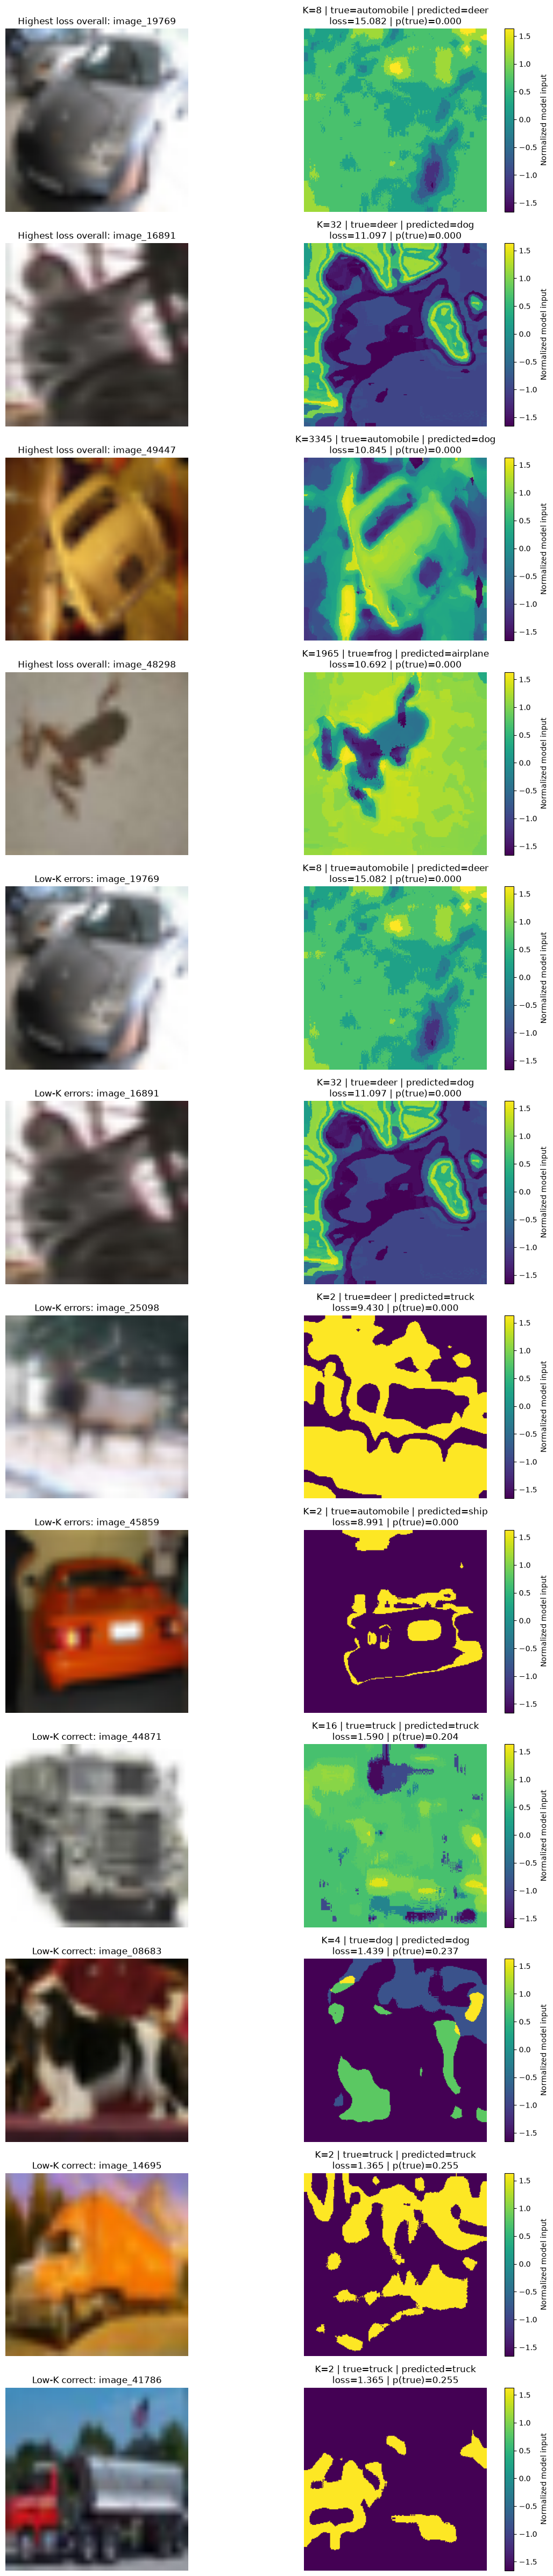

In [ ]:
count = ANALYSIS["gallery_per_group"]
gallery_groups = {
    "Highest loss overall": worst.head(count),
    "Low-K errors": ranked_errors[ranked_errors["K"] < K_MIN].head(count),
    "Low-K correct": rows[(rows["K"] < K_MIN) & rows["correct"]].sort_values("loss", ascending=False, kind="stable").head(count),
}
gallery_items = [(group, row) for group, frame in gallery_groups.items() for _, row in frame.iterrows()]
gallery_figure = None
if gallery_items:
    maps = []
    for _, row in gallery_items:
        with np.load(MANIFEST_PATH.parent / row["file"], allow_pickle=False) as archive:
            maps.append((archive["z_u16"].astype(np.float32) - MEAN)/STD)
    vmin, vmax = min(float(z.min()) for z in maps), max(float(z.max()) for z in maps)
    fig, axes = plt.subplots(len(gallery_items), 2, figsize=(12, 4*len(gallery_items)), squeeze=False)
    for axis_row, (group, row), z in zip(axes, gallery_items, maps):
        original = resolve_path(CONFIG["originals"]) / f"{row['image_id']}.png"
        if original.exists():
            axis_row[0].imshow(plt.imread(original))
        else:
            axis_row[0].text(.5, .5, "Original image unavailable", ha="center", va="center")
        axis_row[0].set_title(f"{group}: {row['image_id']}")
        im = axis_row[1].imshow(z, cmap="viridis", vmin=vmin, vmax=vmax)
        fig.colorbar(im, ax=axis_row[1], fraction=.046, label="Normalized model input")
        axis_row[1].set_title(f"K={row['K']} | true={row['true_class']} | predicted={row['predicted_class']}\nloss={row['loss']:.3f} | p(true)={row['p_true']:.3f}")
        for ax in axis_row:
            ax.axis("off")
    fig.tight_layout()
    plt.show()
    gallery_figure = fig
else:
    print("No gallery samples for these settings.")

## 8. Export reproducible analysis results

Each execution creates a new output directory. The per-image CSV contains K, predictions, probabilities and loss, so additional analysis does not require inference. Exported settings record the checkpoint, validation source and thresholds. Compression statistics are trusted as supplied. No test data are evaluated.

Choose candidate compression changes from these exploratory results, then compare current and modified representations on validation, including retraining as appropriate. Assess compressed size and runtime alongside classification performance. Reserve the final test evaluation for the fixed procedure.

In [25]:
stamp = datetime.now(timezone.utc).strftime("%Y%m%d")
RUN_DIR = resolve_path(CONFIG["results"]) / f"{checkpoint["version"]}_validation_Kbased_{stamp}"
RUN_DIR.mkdir(parents=True, exist_ok=True) 
exports = {"per_image": rows, "overall": overall, "K_bins": bin_summary,
           "K_bins_per_class": bin_per_class, "thresholds": threshold_summary,
           "selected_groups": selected_summary, "selected_per_class": selected_per_class,
           "error_concentration": error_concentration, "top_loss": worst,
           "ranked_errors": ranked_errors}
for name, frame in exports.items():
    frame.to_csv(RUN_DIR / f"{name}.csv", index=False)
settings = {"schema": "v4-validation-Kbased-v1", "created_utc": stamp,
    "config": CONFIG, "analysis": ANALYSIS, "selected_k_min": K_MIN,
    "selection_score": "S_1 = error_coverage_pct - coverage_pct (equal weights)", "checkpoint": str(CHECKPOINT_PATH),
    "manifest": str(MANIFEST_PATH), "k_report": str(REPORT_PATH),
    "epoch": checkpoint["completed_epochs"], "split": "validation",
    "validation_ids": sorted(val_ids), "normalization": {"mean": MEAN, "std": STD},
    "classes": CLASS_NAMES, "device": str(DEVICE), "torch_version": str(torch.__version__),
    "evaluation_seconds": evaluation_seconds, "k_source": "Existing report, trusted without recomputation"}
(RUN_DIR / "settings.json").write_text(json.dumps(settings, indent=2), encoding="utf-8")
(RUN_DIR / "confusion_matrices.json").write_text(json.dumps(confusions, indent=2), encoding="utf-8")
for name, figure in [("K_distribution_performance", distribution_figure),
                     ("confusion_matrices", confusion_figure), ("gallery", gallery_figure)]:
    if figure is not None:
        figure.savefig(RUN_DIR / f"{name}.png", dpi=130, bbox_inches="tight")
print("Saved analysis:", RUN_DIR)

Saved analysis: C:\Users\Edward\Desktop\AARHUS\runs\inference_Kbased\v4_validation_Kbased_20261029


## Main conclusions

Results from the V4 checkpoint on its saved validation set (5,000 images):

- **Low K is associated with poorer classification.** For K < 128 (880 images; 17.6% of validation), accuracy is **67.50%** (95% Wilson CI: 64.34–70.51%), compared with **84.13%** (82.98–85.21%) for K ≥ 128: a gap of **16.63 percentage points**. The error rate is **2.05 times higher** in the low-K group.
- **Errors are disproportionately concentrated in low-K images.** The K < 128 subset contains **30.43% of all classification errors**, despite representing only 17.6% of images. Its mean cross-entropy is **1.132**, versus **0.533** for the remaining images. Recall is lower in the low-K group for **all ten classes**.
- **The smallest K values show the strongest degradation.** Images with K < 8 represent 9.94% of validation and achieve **56.94% accuracy**, compared with **83.88%** for K ≥ 8. Their error rate is **2.67 times higher**.

These findings support testing a targeted compression change for images with very few bases. They do **not** establish that increasing K will improve classification, or that 128 is the optimal threshold. Performance does not improve monotonically with K. Thresholds were explored on validation; the benefit of modified compression must be measured in a controlled comparison before final test evaluation.


## Best K selection
According to section 4, the best K_min has been selected using the S_1 score. It provided **K_min,i = 32** as best threshold, according to this specific Validation Set. 
The next step require to run the compression, forcing each image to be represented with a minimum of 32 bases. 